<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-058-finite-budget-ghz.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 058. Finite-budget GHZ compilation
We prepare $|\mathrm{GHZ}_3\rangle=(|000\rangle+|111\rangle)/\sqrt2$ from $|000\rangle$. The three available operations are H on qubit 0, CNOT from 0 to 1, and CNOT from 1 to 2. This deliberately restricted teaching task has a known three-gate solution.

A state $|\psi\rangle$ is scored by its fidelity $F=|\langle\mathrm{GHZ}_3|\psi\rangle|^2$. The operations are the matrices introduced in Lab 057. $\hat H_0=\hat H\otimes \hat I\otimes \hat I$ sends qubit 0 to $(|0\rangle+|1\rangle)/\sqrt2$. $\mathrm{CX}_{01}$ flips qubit 1 when qubit 0 is $|1\rangle$, and $\mathrm{CX}_{12}$ flips qubit 2 when qubit 1 is $|1\rangle$. The sequence $\hat H_0$, $\mathrm{CX}_{01}$, $\mathrm{CX}_{12}$ maps $|000\rangle$ to $(|000\rangle+|100\rangle)/\sqrt2$, then to $(|000\rangle+|110\rangle)/\sqrt2$, then to $|\mathrm{GHZ}_3\rangle$. The fidelity starts at $1/2$, because $|000\rangle$ is one of the two GHZ branches. It drops to $1/4$ after $\hat H_0$, stays at $1/4$ after $\mathrm{CX}_{01}$ and reaches one after $\mathrm{CX}_{12}$. An agent that maximises only the immediate fidelity change prefers the CNOTs at the start, since they leave $|000\rangle$ unchanged. The first cell builds the reachable states and plots this fidelity history.

We use a six-gate budget, reward $F_{t+1}-F_t-0.01$, discount 0.95, and success threshold $F>0.99$. The remaining budget is part of the state. Success and exhaustion both have zero continuation. The simulator supplies exact amplitudes and fidelities. A device would need a different observation and reward interface.

Run all cells in order with NumPy and Matplotlib. The core route ends after the learned Q-table and circuit.

Reachable physical states: 64 ; Q-table rows include remaining budget
Reference fidelity history: [0.5  0.25 0.25 1.  ]


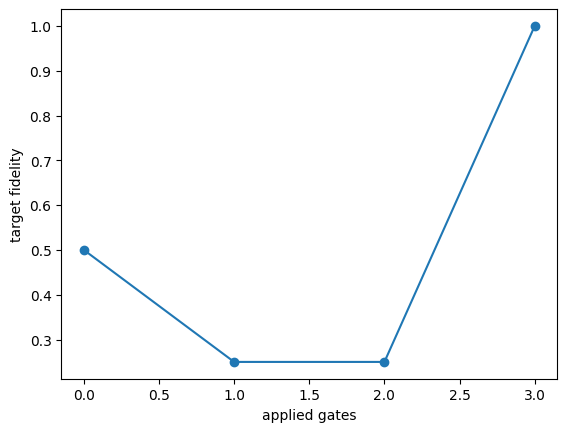

In [1]:
import itertools, time, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
started=time.perf_counter()
OUT=Path('classroom_results'); OUT.mkdir(exist_ok=True)
H=np.array([[1,1],[1,-1]])/np.sqrt(2)
eye=np.eye(8); H0=np.kron(H,np.eye(4))
def cx(control,target):
    U=np.zeros((8,8))
    for k in range(8):
        j=k ^ (1 << (2-target)) if k & (1 << (2-control)) else k
        U[j,k]=1
    return U
GATES=np.array([H0,cx(0,1),cx(1,2)])
NAMES=['H0','CX01','CX12']
psi0=eye[:,0]; target=(eye[:,0]+eye[:,-1])/np.sqrt(2)
GAMMA,COST,BUDGET=0.95,0.01,6
def fidelity(psi): return float(abs(target.conj()@psi)**2)
def key(psi):
    k=np.flatnonzero(abs(psi)>1e-10)[0]
    psi=psi*np.sign(psi[k])
    return tuple(np.round(psi,10))
states=[psi0]; lookup={key(psi0):0}; i=0
while i<len(states):
    for U in GATES:
        psi=U@states[i]; k=key(psi)
        if k not in lookup: lookup[k]=len(states); states.append(psi)
    i+=1
STATES=np.array(states); S=len(states)
NEXT=np.array([[lookup[key(U@psi)] for U in GATES] for psi in STATES])
FID=np.array([fidelity(psi) for psi in STATES])
REWARD=FID[NEXT]-FID[:,None]-COST
SUCCESS=FID>0.99
assert all(np.allclose(U.T@U,np.eye(8)) for U in GATES)
print('Reachable physical states:',S,'; Q-table rows include remaining budget')
psi=psi0.copy(); fids=[fidelity(psi)]
for U in GATES: psi=U@psi; fids.append(fidelity(psi))
print('Reference fidelity history:',np.round(fids,4))
assert np.isclose(fids[-1],1)
plt.plot(range(4),fids,'o-');plt.xlabel('applied gates');plt.ylabel('target fidelity');plt.show()

## Bellman reference and reward targets
At budget zero, $V_0=0$. For $h\ge1$, $Q_h(s,a)=r(s,a)+\gamma(1-d)V_{h-1}(s')$, where $d$ marks success. The $h-1=0$ boundary also enforces budget exhaustion. Backward induction is planning with the known simulator. We use it as a reference for learning from sampled transitions.

The cell also prints two sampled targets along the reference episode. The Monte Carlo target of step $t$ is the discounted sum of all later rewards, $G_t$. The temporal-difference target $r_{t+1}+\gamma V(s_{t+1})$ evaluated with a zero initial table equals the immediate reward. Without the gate cost the rewards telescope into a discounted fidelity objective. With $F_j$ the fidelity after $j$ gates,
$$\sum_{j=1}^{3}\gamma^{j-1}(F_j-F_{j-1})=-F_0+(1-\gamma)\sum_{j=1}^{2}\gamma^{j-1}F_j+\gamma^{2}F_3 .$$
For $\gamma<1$ the intermediate fidelities carry the weights $(1-\gamma)\gamma^{j-1}$, so the objective equals the gain in final fidelity only at $\gamma=1$. The cell checks this identity for the reference episode.

In [2]:
V=np.zeros((BUDGET+1,S)); Qstar=np.zeros((BUDGET+1,S,3))
for h in range(1,BUDGET+1):
    Qstar[h]=REWARD+GAMMA*(~SUCCESS[NEXT])*V[h-1,NEXT]
    V[h]=Qstar[h].max(1)
    V[h,SUCCESS]=0
def evaluate(Q):
    s=0; history=[]; G=0.; discount=1.
    for h in range(BUDGET,0,-1):
        a=int(np.argmax(Q[h,s])); sn=NEXT[s,a]; r=REWARD[s,a]
        history.append((h,NAMES[a],float(r),float(FID[sn])))
        G+=discount*r; discount*=GAMMA; s=sn
        if SUCCESS[s]:break
    return history,G
history,Gref=evaluate(Qstar)
print('remaining budget, gate, reward, fidelity')
for row in history: print(row)
print('Optimal discounted return:',Gref)
rewards=np.diff(fids)-COST
returns=np.array([sum(GAMMA**j*rewards[t+j] for j in range(len(rewards)-t)) for t in range(len(rewards))])
frozen=np.zeros(4)
td=rewards+GAMMA*frozen[1:]-frozen[:-1]
print('Monte Carlo targets:',returns,'; first-pass TD targets:',rewards)
assert np.isclose(sum(GAMMA**np.arange(3)*td),returns[0]-frozen[0])
lhs=np.dot(GAMMA**np.arange(3),np.diff(fids))
rhs=-fids[0]+(1-GAMMA)*sum(GAMMA**(j-1)*fids[j] for j in range(1,3))+GAMMA**2*fids[3]
assert np.isclose(lhs,rhs)
print('Discounted fidelity-gain identity checked')

remaining budget, gate, reward, fidelity
(6, 'H0', -0.26, 0.2499999999999999)
(5, 'CX01', -0.01, 0.2499999999999999)
(4, 'CX12', 0.7399999999999997, 0.9999999999999996)
Optimal discounted return: 0.3983499999999997
Monte Carlo targets: [0.39835 0.693   0.74   ] ; first-pass TD targets: [-0.26 -0.01  0.74]
Discounted fidelity-gain identity checked


## Learning a Q-table from transitions
Rows are pairs of physical state and remaining budget $h$. Columns are the three gates. Each update observes one transition $(s,h,a,r,s')$ and changes one entry,
$$Q_h(s,a)\leftarrow Q_h(s,a)+\alpha\,\big[y-Q_h(s,a)\big],\qquad y=\begin{cases}r, & d=1,\\ r+\gamma\max_{a'}Q_{h-1}(s',a'), & d=0.\end{cases}$$
The flag $d=1$ marks a terminal transition, either success $F(s')>0.99$ or exhaustion of the budget at $h=1$. The step size is $\alpha=n^{-0.6}$, where $n$ counts the updates of that entry, so the first update has $\alpha=1$. Actions are chosen $\varepsilon$-greedily with $\varepsilon=\max(0.15,\,1-\text{episode}/4000)$, and ties between equal entries are broken at random.

The next cell first shows three rows of a zero table before and after one terminal update, the final $\mathrm{CX}_{12}$ with remaining budget $h=4$. It then trains four independent seeds for 6000 episodes each. Evaluation freezes each table and applies its greedy policy without exploration. The learning curves use discounted return from the fixed initial state.

Before the update
   state, h           ['H0', 'CX01', 'CX12']
   |000>          h=6  [0. 0. 0.]
   after H0       h=5  [0. 0. 0.]
   after H0,CX01  h=4  [0. 0. 0.]
Transition: gate CX12, reward 0.74, terminal True, target y = 0.74
After the update
   state, h           ['H0', 'CX01', 'CX12']
   |000>          h=6  [0. 0. 0.]
   after H0       h=5  [0. 0. 0.]
   after H0,CX01  h=4  [0.   0.   0.74]
seed 0 gates ['H0', 'CX01', 'CX12'] final F 0.9999999999999996 return 0.3983499999999997
seed 1 gates ['H0', 'CX01', 'CX12'] final F 0.9999999999999996 return 0.3983499999999997
seed 2 gates ['H0', 'CX01', 'CX12'] final F 0.9999999999999996 return 0.3983499999999997
seed 3 gates ['H0', 'CX01', 'CX12'] final F 0.9999999999999996 return 0.3983499999999997


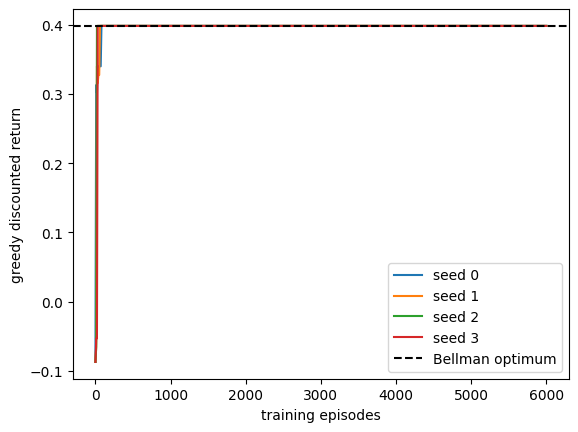

In [3]:
def learn(seed,episodes=6000):
    rng=np.random.default_rng(seed); Q=np.zeros_like(Qstar); visits=np.zeros_like(Qstar)
    logs=[(0,evaluate(Q)[1])]
    for ep in range(episodes):
        s=0
        for h in range(BUDGET,0,-1):
            eps=max(0.15,1-ep/4000)
            a=int(rng.integers(3)) if rng.random()<eps else int(rng.choice(np.flatnonzero(Q[h,s]==Q[h,s].max())))
            sn=NEXT[s,a]; r=REWARD[s,a]; done=bool(SUCCESS[sn] or h==1)
            y=r if done else r+GAMMA*Q[h-1,sn].max()
            visits[h,s,a]+=1; alpha=visits[h,s,a]**(-0.6)
            Q[h,s,a]+=alpha*(y-Q[h,s,a]);s=sn
            if done:break
        if ((ep+1)<=200 and (ep+1)%10==0) or (ep+1)%200==0:logs.append((ep+1,evaluate(Q)[1]))
    return Q,np.array(logs)
# One update of a zero table. Rows are (physical state, remaining budget h), columns are gates.
Qdemo=np.zeros_like(Qstar); s=NEXT[NEXT[0,0],1]; a=2; h=4
rows=[(6,0,'|000>'),(5,NEXT[0,0],'after H0'),(4,s,'after H0,CX01')]
def print_rows(Q,title):
    print(title); print('   state, h          ',NAMES)
    for hh,ss,label in rows: print(f'   {label:14s} h={hh} ',np.round(Q[hh,ss],3))
print_rows(Qdemo,'Before the update')
sn=NEXT[s,a]; r=REWARD[s,a]; done=bool(SUCCESS[sn] or h==1)
y=r if done else r+GAMMA*Qdemo[h-1,sn].max(); alpha=1.0   # first visit, alpha = 1**(-0.6)
Qdemo[h,s,a]+=alpha*(y-Qdemo[h,s,a])
print(f'Transition: gate {NAMES[a]}, reward {r:.2f}, terminal {done}, target y = {y:.2f}')
print_rows(Qdemo,'After the update')
RUNS=[learn(seed) for seed in range(4)]
for seed,(Q,log) in enumerate(RUNS):
    hist,G=evaluate(Q)
    print('seed',seed,'gates',[r[1] for r in hist],'final F',hist[-1][-1],'return',G)
    plt.plot(log[:,0],log[:,1],label=f'seed {seed}')
plt.axhline(Gref,color='black',ls='--',label='Bellman optimum')
plt.xlabel('training episodes');plt.ylabel('greedy discounted return');plt.legend();plt.show()
np.savez_compressed(OUT/'lab058_tables.npz',Q=np.array([q for q,_ in RUNS]),Qstar=Qstar,logs=np.array([log for _,log in RUNS]))
assert all(np.isclose(evaluate(q)[1],Gref) for q,_ in RUNS)

The core classroom route ends here. Explain the fidelity loss after H, the budget boundary, and the difference between a reference solution and reliable learning across seeds before continuing.

## A replay minibatch and its gradient
We replace the table by a small neural network with one hidden tanh layer. The input contains real amplitudes, imaginary amplitudes and normalised remaining budget. We construct replay transitions from the reachable states. This complete-model replay batch checks the update equations and supplies no benchmark of neural-agent reliability.

The online network selects the next action in Double DQN. The target network evaluates it. Targets are frozen during each regression gradient. A central difference checks the derivative of the chosen-output loss.

In [4]:
rng=np.random.default_rng(58)
X=np.concatenate([STATES,np.zeros_like(STATES)],axis=1)
def features(s,h):return np.concatenate([X[np.asarray(s)],np.asarray(h)[...,None]/BUDGET],axis=-1)
params=[rng.normal(0,.15,(17,12)),np.zeros(12),rng.normal(0,.15,(12,3)),np.zeros(3)]
target_params=[x+rng.normal(0,.08,x.shape) for x in params]
def net(p,x):return np.tanh(x@p[0]+p[1])@p[2]+p[3]
hs,ss,aa=np.meshgrid(np.arange(1,BUDGET+1),np.flatnonzero(~SUCCESS),np.arange(3),indexing='ij')
hs,ss,aa=hs.ravel(),ss.ravel(),aa.ravel(); ns=NEXT[ss,aa]
done=SUCCESS[ns]|(hs==1); r=REWARD[ss,aa]
x=features(ss,hs); xn=features(ns,hs-1)
online=net(params,xn); target_q=net(target_params,xn)
y_dqn=r+GAMMA*(~done)*target_q.max(1)
selected=online.argmax(1)
y_ddqn=r+GAMMA*(~done)*target_q[np.arange(len(r)),selected]
assert np.all(y_dqn>=y_ddqn-1e-12)
assert np.allclose(y_dqn[done],r[done])
def loss_grad(p,x,a,y):
    hidden=np.tanh(x@p[0]+p[1]); out=hidden@p[2]+p[3]
    err=out[np.arange(len(a)),a]-y
    dout=np.zeros_like(out);dout[np.arange(len(a)),a]=err/len(a)
    dh=(dout@p[2].T)*(1-hidden**2)
    return np.mean(err**2)/2,[x.T@dh,dh.sum(0),hidden.T@dout,dout.sum(0)]
loss,grad=loss_grad(params,x,aa,y_ddqn)
eps=1e-6; plus=[z.copy() for z in params];minus=[z.copy() for z in params]
plus[0][0,0]+=eps;minus[0][0,0]-=eps
fd=(loss_grad(plus,x,aa,y_ddqn)[0]-loss_grad(minus,x,aa,y_ddqn)[0])/(2*eps)
assert np.isclose(fd,grad[0][0,0],atol=1e-8)
updated=[z-.05*g for z,g in zip(params,grad)]
print('Finite-difference and analytic derivative:',fd,grad[0][0,0])
print('Frozen-target loss before and after:',loss,loss_grad(updated,x,aa,y_ddqn)[0])
for i in [0,len(r)//2,-1]:
    print('h, action, reward, terminal, DQN target, DDQN target:',hs[i],aa[i],r[i],done[i],y_dqn[i],y_ddqn[i])

Finite-difference and analytic derivative: 0.00024532707809665766 0.00024532707913558225
Frozen-target loss before and after: 0.03538732992015737 0.034943019501963136
h, action, reward, terminal, DQN target, DDQN target: 1 0 -0.26 True -0.26 -0.26
h, action, reward, terminal, DQN target, DDQN target: 4 0 -0.26 False 0.0052541965922419664 -0.23000393009780165
h, action, reward, terminal, DQN target, DDQN target: 6 2 -0.01 False 0.15599540653323982 0.14701995384592026


## A gradient reference and baseline variance
We enumerate all three-action circuits of three gates for a policy with one softmax distribution at each time. The circuit always runs its three gates in this diagnostic, with terminal reward equal to final fidelity and discount one. Enumeration gives the exact expected fidelity and its gradient. This policy has nine logits and supplies a small calculation of REINFORCE without differentiating through physics.

We compare plain returns, a fixed baseline, a self-inclusive batch mean, a leave-one-out mean and normalised returns. Standard errors come from independent batches. A self-inclusive batch mean has expected gradient $(1-1/B)g$ in this fixed-size independent-episode calculation. With $B=16$ this is a 6% reduction, comparable to the statistical resolution of 5000 batches, so the printed means should be compared using their standard errors. Normalised returns divide by the batch standard deviation, which rescales the gradient, and their mean is therefore not an estimate of $g$.

plain component mean 0.008669407936959264 SE 0.0008265059823726039 total variance 0.02411149312789901
fixed baseline component mean 0.009307426258335777 SE 0.00039727484053346925 total variance 0.004287238733905617
batch mean component mean 0.008796093749999984 SE 0.0003841795414381752 total variance 0.004082363595827087
leave one out component mean 0.009382499999999981 SE 0.0004097915108673868 total variance 0.004644822580141006
normalised component mean 0.021341453746698547 SE 0.002000207790933136 total variance 0.10365224593900119
Exact component 0.009465682031507213 ; self-inclusive expectation 0.008874076904538012
{'experiment': 'restricted finite-budget GHZ3 classroom experiment', 'seeds': [0, 1, 2, 3], 'budget': 6, 'gamma': 0.95, 'reference_return': 0.3983499999999997, 'final_returns': [0.3983499999999997, 0.3983499999999997, 0.3983499999999997, 0.3983499999999997], 'runtime_seconds': 1.6282698210000035}


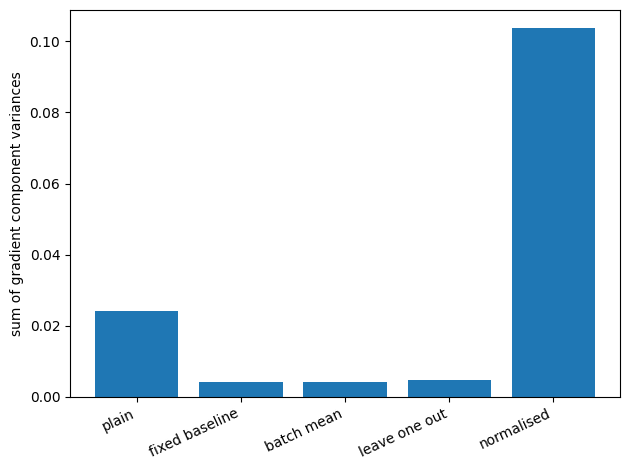

In [5]:
seq=np.array(list(itertools.product(range(3),repeat=3)))
R=[]
for actions in seq:
    psi=psi0.copy()
    for a in actions:psi=GATES[a]@psi
    R.append(fidelity(psi))
R=np.array(R);z=np.array([[.2,-.1,0],[0,.3,-.2],[-.1,0,.2]])
def softmax(z):
    e=np.exp(z-z.max(-1,keepdims=True));return e/e.sum(-1,keepdims=True)
prob=softmax(z); weights=np.prod(prob[np.arange(3),seq],axis=1)
score=np.eye(3)[seq]-prob[None,:,:]
g=(weights[:,None,None]*R[:,None,None]*score).sum(0)
def objective(z):
    pr=softmax(z);return np.dot(np.prod(pr[np.arange(3),seq],axis=1),R)
zp=z.copy();zm=z.copy();zp[0,0]+=eps;zm[0,0]-=eps
assert np.isclose((objective(zp)-objective(zm))/(2*eps),g[0,0],atol=1e-9)
B,REPS=16,5000;rng=np.random.default_rng(590)
idx=rng.choice(len(seq),(REPS,B),p=weights)
rr=R[idx];sc=score[idx];mean=rr.mean(1,keepdims=True)
loo=(rr.sum(1,keepdims=True)-rr)/(B-1)
estimates={
    'plain':(rr[...,None,None]*sc).mean(1),
    'fixed baseline':((rr-objective(z))[...,None,None]*sc).mean(1),
    'batch mean':((rr-mean)[...,None,None]*sc).mean(1),
    'leave one out':((rr-loo)[...,None,None]*sc).mean(1),
    'normalised':(((rr-mean)/(rr.std(1,keepdims=True)+1e-8))[...,None,None]*sc).mean(1)}
for name,est in estimates.items():
    print(name,'component mean',est[:,0,0].mean(),'SE',est[:,0,0].std(ddof=1)/np.sqrt(REPS),'total variance',est.var(0,ddof=1).sum())
print('Exact component',g[0,0],'; self-inclusive expectation',(1-1/B)*g[0,0])
plt.bar(estimates.keys(),[e.var(0,ddof=1).sum() for e in estimates.values()])
plt.xticks(rotation=25,ha='right');plt.ylabel('sum of gradient component variances');plt.tight_layout();plt.show()
summary={'experiment':'restricted finite-budget GHZ3 classroom experiment','seeds':list(range(4)),
         'budget':BUDGET,'gamma':GAMMA,'reference_return':float(Gref),
         'final_returns':[float(evaluate(q)[1]) for q,_ in RUNS],
         'runtime_seconds':time.perf_counter()-started}
(OUT/'lab058_results.json').write_text(json.dumps(summary,indent=2))
print(summary)
np.savez_compressed(OUT/'lab058_baselines.npz',names=np.array(list(estimates)),variances=np.array([e.var(0,ddof=1).sum() for e in estimates.values()]))

## A value baseline can increase variance
For a binary action with success probability 0.9 and reward equal to the action, the logistic-policy score is a minus 0.9. We evaluate both outcomes exactly. The state value is an action-independent baseline, and its effect on variance also depends on the score magnitudes. For a single score $z$ the variance of $(G-b)z$ is smallest at $b^*=\mathbb E[Gz^2]/\mathbb E[z^2]$. Here the scores are $-0.9$ and $0.1$ with probabilities $0.1$ and $0.9$, so $b^*=0.009/0.09=0.1$, and the estimator then has zero variance. The value baseline $b=0.9$ increases the variance.

In [6]:
prob=np.array([.1,.9]);reward=np.array([0.,1.]);score=reward-.9
def exact_moments(b):
    estimate=(reward-b)*score
    mean=prob@estimate
    return float(mean),float(prob@(estimate-mean)**2)
for label,b in [('plain',0.),('value baseline',.9),('optimal baseline',.1)]:
    print(label,exact_moments(b))
assert np.isclose(exact_moments(0)[1],.0009)
assert np.isclose(exact_moments(.9)[1],.0576)
assert np.isclose(exact_moments(.1)[1],0)


plain (0.08999999999999998, 0.0008999999999999995)
value baseline (0.09000000000000001, 0.05760000000000001)
optimal baseline (0.08999999999999998, 7.703719777548944e-35)


## Student calculations
Derive the finite-budget recursion and change the budget. Compare discounted fidelity-gain reward with terminal fidelity. Explain which comparisons change the objective. Inspect two replay transitions with different remaining budgets. Show why the two neural targets coincide at termination. Predict the effect of self-inclusion before inspecting the baseline table. Explain why this restricted three-gate task cannot replace the full H,S,T,CNOT benchmark.